## 0. Setup

In [13]:
# Mount Drive, get the repo and install requirements
import os, sys
from google.colab import drive
drive.mount("/content/drive")

REPO_URL = "https://github.com/Aryan16d/IE7615-Genrative-milestone.git"
REPO_DIR = "/content/IE7615-Genrative-milestone"
if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull -q
else:
    !git clone -q {REPO_URL} {REPO_DIR}
%pip install -q -r {REPO_DIR}/requirements.txt
sys.path.insert(0, REPO_DIR)   # so later notebooks can `import utils`

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import json, re, random, zipfile, shutil, urllib.request
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm

SEED = 39
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE  = torch.float16 if DEVICE == "cuda" else torch.float32
print("Device:", DEVICE)

Device: cuda


In [15]:
# ---- Paths ----
# data lives on Drive so preprocessing survives Colab sessions; results go to the repo
DRIVE_ROOT  = Path("/content/drive/MyDrive/t2i")
DATA_DIR    = DRIVE_ROOT / "data"
REPO_DIR    = Path(REPO_DIR)
RESULTS_DIR = REPO_DIR / "results"
PROMPTS_TXT = REPO_DIR / "prompts" / "test_prompts.txt"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# ---- Versions / GPU ----
import transformers, diffusers
print("torch       ", torch.__version__, "| CUDA", torch.version.cuda)
print("transformers", transformers.__version__)
print("diffusers   ", diffusers.__version__)
if DEVICE == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} ({p.total_memory / 1e9:.1f} GB)")
print("DATA_DIR:", DATA_DIR)

torch        2.11.0+cu130 | CUDA 13.0
transformers 5.22.1
diffusers    0.42.1
GPU: Tesla T4 (15.6 GB)
DATA_DIR: /content/drive/MyDrive/t2i/data


## 1. Dataset choice

| | **COCO 2017 val** (chosen) | Flickr30k |
|---|---|---|
| Images | 5,000 | 31,783 |
| Captions / image | ~5 | 5 |
| Download | ~1 GB, direct link | request form / HF mirror |
| T2I benchmark | standard (FID, CLIPScore) | less common |
| Content | 80 object categories, everyday scenes | mostly people & activities |

**Why COCO val2017:** it's already in our 1k–5k target range, downloads directly, and generation results are comparable with published numbers.
Set `N_TARGET` below to 1000 for fast iteration and 5000 for the final run.

In [16]:
RAW_DIR   = DATA_DIR / "raw" / "coco"
PROC_DIR  = DATA_DIR / "processed"
IMG_OUT   = PROC_DIR / "images"
for d in (RAW_DIR, IMG_OUT): d.mkdir(parents=True, exist_ok=True)

N_TARGET      = 5000     # final number of image–caption pairs (1000 for quick runs)
IMG_SIZE      = 512      # Stable Diffusion v1.x native resolution
MIN_SIDE      = 256      # drop images smaller than this on the short side
MAX_ASPECT    = 2.5      # drop extreme panoramas/strips (center-crop would lose too much)
MIN_WORDS, MAX_WORDS = 5, 40
CLIP_DROP_Q   = 0.10     # drop the weakest 10% of pairs by CLIP similarity
SPLIT         = (0.8, 0.1, 0.1)
CLIP_ID       = "openai/clip-vit-large-patch14"   # same text encoder as SD v1.5

# ---- Rebuild or load ----
# Sections 2–10 take 20+ min. If pairs_clean.csv is already on Drive they are skipped
# (cells marked %%rebuild) and section 11 loads the saved files. Set True to force a rebuild.
REBUILD_DATA = False
REBUILD_DATA = REBUILD_DATA or not (PROC_DIR / "pairs_clean.csv").exists()
print("REBUILD_DATA:", REBUILD_DATA)

from IPython.core.magic import register_cell_magic
@register_cell_magic
def rebuild(line, cell):
    if REBUILD_DATA:
        get_ipython().run_cell(cell).raise_error()  # stop Run All if a step fails
    else:
        print("skipped (REBUILD_DATA = False)")

REBUILD_DATA: False


## 2. Download COCO 2017 val + captions
Skips anything already downloaded.

In [17]:
%%rebuild
URLS = {
    "val2017.zip": "http://images.cocodataset.org/zips/val2017.zip",
    "annotations_trainval2017.zip": "http://images.cocodataset.org/annotations/annotations_trainval2017.zip",
}

def download(url, dest):
    if dest.exists():
        print("exists:", dest.name); return
    print("downloading:", dest.name)
    with tqdm(unit="B", unit_scale=True) as bar:
        def hook(b, bs, total):
            bar.total = total; bar.update(b * bs - bar.n)
        urllib.request.urlretrieve(url, dest, hook)

for name, url in URLS.items():
    download(url, RAW_DIR / name)

if not (RAW_DIR / "val2017").exists():
    zipfile.ZipFile(RAW_DIR / "val2017.zip").extractall(RAW_DIR)
cap_file = RAW_DIR / "annotations" / "captions_val2017.json"
if not cap_file.exists():
    with zipfile.ZipFile(RAW_DIR / "annotations_trainval2017.zip") as z:
        z.extract("annotations/captions_val2017.json", RAW_DIR)

IMG_DIR = RAW_DIR / "val2017"
print("images on disk:", len(list(IMG_DIR.glob("*.jpg"))))

skipped (REBUILD_DATA = False)


## 3. Load into a DataFrame & first look

In [18]:
%%rebuild
ann = json.load(open(cap_file))
images = pd.DataFrame(ann["images"])[["id", "file_name", "width", "height"]].rename(columns={"id": "image_id"})
caps   = pd.DataFrame(ann["annotations"])[["image_id", "caption"]]
raw = caps.merge(images, on="image_id")

print(f"{len(images):,} images | {len(caps):,} captions | {len(caps)/len(images):.2f} captions/image")
raw.head()

skipped (REBUILD_DATA = False)


In [19]:
%%rebuild
raw["n_words_raw"] = raw.caption.str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
raw.n_words_raw.plot.hist(bins=40, ax=ax[0], title="Caption length (words, raw)")
raw.groupby("image_id").size().value_counts().sort_index().plot.bar(ax=ax[1], title="Captions per image")
images.assign(ar=images.width / images.height).ar.plot.hist(bins=40, ax=ax[2], title="Aspect ratio (w/h)")
plt.tight_layout(); plt.show()

skipped (REBUILD_DATA = False)


## 4. Caption cleaning
Rules:
1. Normalize whitespace, strip, lowercase, remove stray quotes/odd characters, collapse repeated punctuation
2. Standardize ending to a single period
3. Drop empty / too short (< 5 words) / too long (> 40 words; also keeps us under CLIP's 77-token limit)
4. Drop exact duplicate captions **within** the same image
5. Verify token length with the real CLIP tokenizer (anything that would be truncated is dropped)

In [20]:
%%rebuild
import unicodedata
def clean_caption(c: str) -> str:
    c = unicodedata.normalize("NFKD", c).encode("ascii", "ignore").decode()  # café -> cafe
    c = c.strip().lower()
    c = c.replace("\n", " ").replace("\t", " ")
    c = re.sub(r"[\"`]", "", c)                     # quotes
    c = re.sub(r"[^a-z0-9\s,.'\-!?&/]", " ", c)    # odd chars
    c = re.sub(r"([.,!?])\1+", r"\1", c)           # repeated punctuation
    c = re.sub(r"\s+([.,!?])", r"\1", c)           # space before punctuation
    c = re.sub(r"\s+", " ", c).strip()
    c = c.rstrip(" .,!?")
    return (c + ".") if c else ""

df = raw.copy()
df["caption_raw"] = df.caption
df["caption"] = df.caption.map(clean_caption)
df["n_words"] = df.caption.str.split().str.len()

log = {"raw captions": len(df)}
df = df[df.caption.str.len() > 0];                          log["after empty"] = len(df)
df = df[df.n_words.between(MIN_WORDS, MAX_WORDS)];          log["after length filter"] = len(df)
df = df.drop_duplicates(["image_id", "caption"]);           log["after dedupe"] = len(df)

# examples of what changed
changed = df[df.caption_raw.str.strip().str.lower().str.rstrip(" .") + "." != df.caption]
display(changed[["caption_raw", "caption"]].head(8))
log

skipped (REBUILD_DATA = False)


In [21]:
%%rebuild
from transformers import CLIPTokenizer
tok = CLIPTokenizer.from_pretrained(CLIP_ID)
df["n_tokens"] = [len(x) for x in tok(df.caption.tolist(), truncation=False)["input_ids"]]
df = df[df.n_tokens <= 77];  log["after token check"] = len(df)
print("max tokens:", df.n_tokens.max(), "| mean:", round(df.n_tokens.mean(), 1))

skipped (REBUILD_DATA = False)


## 5. Image validation
Drop images that are corrupt, too small, or extremely elongated. Grayscale/CMYK/RGBA images are kept but converted to RGB in step 6.

In [22]:
%%rebuild
def check_image(path):
    try:
        with Image.open(path) as im:
            im.verify()                       # catches truncated/corrupt files
        with Image.open(path) as im:
            w, h = im.size
            return {"ok": True, "mode": im.mode, "w": w, "h": h}
    except Exception as e:
        return {"ok": False, "mode": None, "w": 0, "h": 0, "err": str(e)}

img_meta = []
for iid, fname in tqdm(df[["image_id", "file_name"]].drop_duplicates().values, desc="validating"):
    r = check_image(IMG_DIR / fname); r.update(image_id=iid); img_meta.append(r)
img_meta = pd.DataFrame(img_meta)
img_meta["short"]  = img_meta[["w", "h"]].min(axis=1)
img_meta["aspect"] = img_meta[["w", "h"]].max(axis=1) / img_meta.short.clip(lower=1)

print("modes:", img_meta["mode"].value_counts().to_dict())
bad = img_meta[~img_meta.ok | (img_meta.short < MIN_SIDE) | (img_meta.aspect > MAX_ASPECT)]
print(f"dropping {len(bad)} images: corrupt={(~img_meta.ok).sum()}, "
      f"small={(img_meta.short < MIN_SIDE).sum()}, extreme aspect={(img_meta.aspect > MAX_ASPECT).sum()}")

df = df[~df.image_id.isin(bad.image_id)]; log["after image validation"] = len(df)
print(f"{df.image_id.nunique():,} images remain")

skipped (REBUILD_DATA = False)


## 6. Image preprocessing → 512×512 RGB
Resize the short side to 512 (Lanczos), center-crop to 512×512, fix EXIF rotation, convert to RGB, save as JPEG (q=95).
Center-crop matches how Stable Diffusion was trained; the aspect-ratio filter above limits how much gets cut off.

In [23]:
%%rebuild
def preprocess(src, dst, size=IMG_SIZE):
    with Image.open(src) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        w, h = im.size
        s = size / min(w, h)
        im = im.resize((round(w * s), round(h * s)), Image.LANCZOS)
        w, h = im.size
        l, t = (w - size) // 2, (h - size) // 2
        im.crop((l, t, l + size, t + size)).save(dst, "JPEG", quality=95)

for fname in tqdm(df.file_name.unique(), desc="preprocessing"):
    dst = IMG_OUT / fname
    if not dst.exists():
        preprocess(IMG_DIR / fname, dst)
print("processed images:", len(list(IMG_OUT.glob('*.jpg'))))

skipped (REBUILD_DATA = False)


In [24]:
%%rebuild
# before / after check
sample = df.drop_duplicates("image_id").sample(4, random_state=SEED)
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for i, (_, r) in enumerate(sample.iterrows()):
    ax[0, i].imshow(Image.open(IMG_DIR / r.file_name)); ax[0, i].set_title(f"original {r.width}×{r.height}", fontsize=9)
    ax[1, i].imshow(Image.open(IMG_OUT / r.file_name)); ax[1, i].set_title("512×512", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

skipped (REBUILD_DATA = False)


## 7. CLIP image–text alignment filter
Score every caption against its (processed) image with CLIP ViT-L/14. Then:
- keep the **best-matching caption** per image as the primary training/eval caption
- drop the weakest `CLIP_DROP_Q` of pairs (mismatched or vague captions)

All captions + scores are still saved, in case the team wants multi-caption training later.

In [25]:
%%rebuild
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=DTYPE).to(DEVICE).eval()
proc = CLIPProcessor.from_pretrained(CLIP_ID)

@torch.no_grad()
def embed_images(paths, bs=32):
    out = []
    for i in tqdm(range(0, len(paths), bs), desc="image emb"):
        ims = [Image.open(p).convert("RGB") for p in paths[i:i+bs]]
        px = proc(images=ims, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
        e = clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output)
        out.append((e / e.norm(dim=-1, keepdim=True)).float().cpu())
    return torch.cat(out)

@torch.no_grad()
def embed_texts(texts, bs=128):
    out = []
    for i in tqdm(range(0, len(texts), bs), desc="text emb"):
        t = proc(text=texts[i:i+bs], padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEVICE)
        e = clip.text_projection(clip.text_model(input_ids=t["input_ids"], attention_mask=t["attention_mask"]).pooler_output)
        out.append((e / e.norm(dim=-1, keepdim=True)).float().cpu())
    return torch.cat(out)

uniq = df.drop_duplicates("image_id")[["image_id", "file_name"]].reset_index(drop=True)
img_emb = embed_images([IMG_OUT / f for f in uniq.file_name])
row_of = {iid: i for i, iid in enumerate(uniq.image_id)}

df = df.reset_index(drop=True)
txt_emb = embed_texts(df.caption.tolist())
idx = torch.tensor(df.image_id.map(row_of).values)
df["clip_sim"] = (txt_emb * img_emb[idx]).sum(-1).numpy()
df.clip_sim.describe()

skipped (REBUILD_DATA = False)


In [26]:
%%rebuild
best = df.loc[df.groupby("image_id").clip_sim.idxmax()].copy()
thresh = best.clip_sim.quantile(CLIP_DROP_Q)
fig, ax = plt.subplots(figsize=(8, 4))
best.clip_sim.plot.hist(bins=50, ax=ax, title="CLIP similarity of best caption per image")
ax.axvline(thresh, color="red", ls="--", label=f"drop < {thresh:.3f}"); ax.legend(); plt.show()

# what the filter removes vs keeps
worst, top = best.nsmallest(3, "clip_sim"), best.nlargest(3, "clip_sim")
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for row, sub, lab in [(0, worst, "DROPPED"), (1, top, "KEPT")]:
    for j, (_, r) in enumerate(sub.iterrows()):
        ax[row, j].imshow(Image.open(IMG_OUT / r.file_name)); ax[row, j].axis("off")
        ax[row, j].set_title(f"{lab} {r.clip_sim:.3f}\n{r.caption[:60]}", fontsize=8)
plt.tight_layout(); plt.show()

best = best[best.clip_sim >= thresh];  log["images after CLIP filter"] = len(best)

skipped (REBUILD_DATA = False)


## 8. Sample to target size & split
Split is by **image**, so no image leaks across train/val/test.

In [27]:
%%rebuild
best = best.sample(min(N_TARGET, len(best)), random_state=SEED).reset_index(drop=True)
n = len(best); n_tr, n_va = int(SPLIT[0] * n), int(SPLIT[1] * n)
best["split"] = ["train"] * n_tr + ["val"] * n_va + ["test"] * (n - n_tr - n_va)
best["image_path"] = best.file_name.map(lambda f: str(IMG_OUT / f))
best.split.value_counts()

skipped (REBUILD_DATA = False)


## 9. Export

In [28]:
%%rebuild
cols = ["image_id", "file_name", "image_path", "caption", "n_words", "n_tokens", "clip_sim", "split"]
best[cols].to_csv(PROC_DIR / "pairs_clean.csv", index=False)

keep_ids = set(best.image_id)
all_caps = df[df.image_id.isin(keep_ids)].merge(best[["image_id", "split"]], on="image_id")
all_caps[["image_id", "file_name", "caption", "caption_raw", "n_tokens", "clip_sim", "split"]] \
    .to_csv(PROC_DIR / "captions_all.csv", index=False)

# remove processed images that didn't make the final cut
for p in IMG_OUT.glob("*.jpg"):
    if p.name not in set(best.file_name): p.unlink()

print("pairs_clean.csv :", len(best), "rows")
print("captions_all.csv:", len(all_caps), "rows")
print("images folder   :", len(list(IMG_OUT.glob('*.jpg'))))

skipped (REBUILD_DATA = False)


## 10. Dataset summary (for the proposal)

In [29]:
%%rebuild
stop = set("a an the of on in with and is are to at for by its it his her their there this that".split())
words = Counter(w.strip(".,!?") for c in best.caption for w in c.split() if w.strip(".,!?") not in stop)

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
best.n_words.plot.hist(bins=30, ax=ax[0], title="Final caption length (words)")
pd.Series(dict(words.most_common(20))).plot.barh(ax=ax[1], title="Top 20 content words"); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig(PROC_DIR / "dataset_summary.png", dpi=150); plt.show()

funnel = pd.DataFrame({"count": log})
funnel["unit"] = ["images" if "images" in k else "captions" for k in funnel.index]
display(funnel)
funnel_md = "\n".join(f"- {k}: {r['count']:,} {r.unit}" for k, r in funnel.iterrows())
split_counts = {k: int(v) for k, v in best.split.value_counts().items()}

card = f"""# Dataset card — COCO 2017 val (curated)
- Source: MS-COCO 2017 validation split (5,000 images, {len(caps):,} captions)
- Final: **{len(best):,} image–caption pairs** at {IMG_SIZE}×{IMG_SIZE} RGB
- Split: {split_counts}
- Caption length: mean {best.n_words.mean():.1f} words / {best.n_tokens.mean():.1f} CLIP tokens (max 77)
- Mean CLIP ViT-L/14 image–text similarity: {best.clip_sim.mean():.3f} (filter threshold {thresh:.3f})

## Cleaning funnel
{funnel_md}

## Steps
1. Caption normalization (case, whitespace, punctuation, odd chars), length filter {MIN_WORDS}–{MAX_WORDS} words, per-image dedupe, CLIP token check
2. Image validation (corrupt, short side < {MIN_SIDE}px, aspect > {MAX_ASPECT})
3. EXIF fix, RGB, Lanczos resize + center-crop to {IMG_SIZE}
4. CLIP alignment: best caption per image, bottom {int(CLIP_DROP_Q*100)}% dropped
5. Image-level {SPLIT} train/val/test split, seed {SEED}
"""
(PROC_DIR / "dataset_card.md").write_text(card)
print(card)

skipped (REBUILD_DATA = False)


## 11. Load curated pairs
Runs in both modes, so later sections always start from the saved files on Drive.

In [30]:
pairs = pd.read_csv(PROC_DIR / "pairs_clean.csv")
pairs["image_path"] = pairs.file_name.map(lambda f: str(IMG_OUT / f))  # rebuild paths for this machine
missing = (~pairs.image_path.map(os.path.exists)).sum()
print(f"{len(pairs):,} pairs | missing images: {missing} |", pairs.split.value_counts().to_dict())
pairs.head(3)

4,462 pairs | missing images: 0 | {'train': 3569, 'test': 447, 'val': 446}


,image_id,file_name,image_path,caption,n_words,n_tokens,clip_sim,split
0,221281,000000221281.jpg,/content/drive/MyDrive/t2i/data/processed/imag...,a group of giraffes walking in the sand.,8,12,0.247523,train
1,206831,000000206831.jpg,/content/drive/MyDrive/t2i/data/processed/imag...,a boxer dog sitting in the grass with a chew t...,14,17,0.320478,train
2,560256,000000560256.jpg,/content/drive/MyDrive/t2i/data/processed/imag...,assorted vegetables are displayed at a fruit s...,14,20,0.278872,train


## 12. Using the curated data in later notebooks
```python
import pandas as pd
pairs = pd.read_csv("/content/drive/MyDrive/t2i/data/processed/pairs_clean.csv")
train = pairs[pairs.split == "train"]   # image_path, caption
```
Rebuild `image_path` from `file_name` as in section 11. The data itself stays on Drive.

## 13. Text to embedding pipeline (CLIP per-token)
Stable Diffusion does not use the single pooled CLIP vector from section 7. Its UNet cross-attends to the **per-token** hidden states of the CLIP text encoder: every prompt is padded to 77 tokens and becomes a 77×768 matrix (`last_hidden_state`). The pooled/projected vector (one 768-d vector per caption) is what we used for image–text alignment.

In [31]:
from transformers import CLIPTokenizer, CLIPTextModelWithProjection
tok = CLIPTokenizer.from_pretrained(CLIP_ID)
text_enc = CLIPTextModelWithProjection.from_pretrained(CLIP_ID, torch_dtype=DTYPE).to(DEVICE).eval()

cap = pairs.caption.iloc[0]
t = tok(cap, padding="max_length", max_length=77, truncation=True, return_tensors="pt")
n_real = int(t.attention_mask.sum())
print(cap)
print("tokens   :", tok.convert_ids_to_tokens(t.input_ids[0][:n_real]))
print("input_ids:", tuple(t.input_ids.shape), "| real tokens:", n_real, "| padding:", 77 - n_real)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.v_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.weight | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.out_proj.bias   | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.k_proj.weight   | UNEXPECTED |  | 
vision_

a group of giraffes walking in the sand.
tokens   : ['<|startoftext|>', 'a</w>', 'group</w>', 'of</w>', 'gira', 'ffes</w>', 'walking</w>', 'in</w>', 'the</w>', 'sand</w>', '.</w>', '<|endoftext|>']
input_ids: (1, 77) | real tokens: 12 | padding: 65


In [32]:
@torch.no_grad()
def embed_tokens(texts, bs=64):
    """Returns per-token (N, 77, 768) = what SD's UNet sees, and pooled/projected (N, 768)."""
    tokens, pooled = [], []
    for i in tqdm(range(0, len(texts), bs), desc="text emb", disable=len(texts) <= bs):
        ids = tok(texts[i:i+bs], padding="max_length", max_length=77,
                  truncation=True, return_tensors="pt").input_ids.to(DEVICE)
        out = text_enc(input_ids=ids)
        tokens.append(out.last_hidden_state.cpu()); pooled.append(out.text_embeds.cpu())
    return torch.cat(tokens), torch.cat(pooled)

prompts = [l.strip() for l in open(PROMPTS_TXT) if l.strip()]
assert len(prompts) == 5, f"found {len(prompts)} prompts: push prompts/test_prompts.txt and rerun the first cell"

E_prompts, P_prompts = embed_tokens(prompts)
print("per-token:", tuple(E_prompts.shape), E_prompts.dtype)   # (5, 77, 768)
print("pooled   :", tuple(P_prompts.shape))                    # (5, 768)

per-token: (5, 77, 768) torch.float16
pooled   : (5, 768)


mean cosine similarity | same image: 0.650 | different images: 0.264


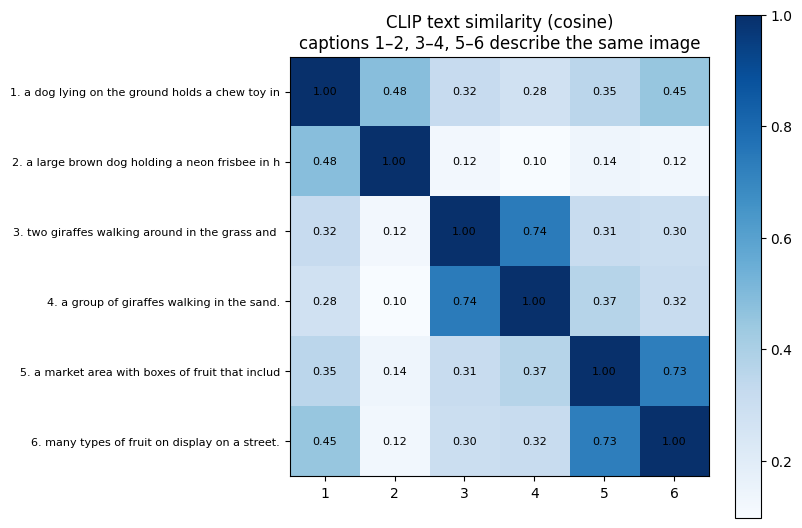

In [33]:
caps_all = pd.read_csv(PROC_DIR / "captions_all.csv")
n_caps = caps_all.groupby("image_id").size()
demo_ids = pd.Series(n_caps[n_caps >= 2].index).sample(3, random_state=SEED)
demo = (caps_all[caps_all.image_id.isin(demo_ids)]
        .groupby("image_id").head(2).sort_values("image_id").reset_index(drop=True))

_, pooled = embed_tokens(demo.caption.tolist())
pooled = pooled.float(); pooled = pooled / pooled.norm(dim=-1, keepdim=True)
sim = (pooled @ pooled.T).numpy()

same = demo.image_id.values[:, None] == demo.image_id.values[None, :]
off_diag = ~np.eye(len(demo), dtype=bool)
print(f"mean cosine similarity | same image: {sim[same & off_diag].mean():.3f} "
      f"| different images: {sim[~same].mean():.3f}")

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(sim, cmap="Blues")
ax.set_xticks(range(len(demo))); ax.set_xticklabels(range(1, len(demo) + 1))
ax.set_yticks(range(len(demo)))
ax.set_yticklabels([f"{i+1}. {c[:45]}" for i, c in enumerate(demo.caption)], fontsize=8)
for i in range(len(demo)):
    for j in range(len(demo)):
        ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("CLIP text similarity (cosine)\ncaptions 1–2, 3–4, 5–6 describe the same image")
plt.colorbar(im); plt.tight_layout(); plt.show()

## 14. Stable Diffusion v1.5 baseline
Load SD v1.5 (fp16) with Diffusers, check that its text encoder gives the same embeddings as section 13, then generate the 5 fixed prompts from `prompts/test_prompts.txt` with seed 42 and SD defaults (50 steps, guidance 7.5). Images go to `results/samples/m1_baseline/`, one log row per image to `results/logs/generation_log.csv`.

In [34]:
from diffusers import StableDiffusionPipeline
SD_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
pipe = StableDiffusionPipeline.from_pretrained(SD_ID, torch_dtype=DTYPE, variant="fp16").to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print("scheduler:", type(pipe.scheduler).__name__)

# SD's text encoder = the same CLIP ViT-L/14 text model as section 13
with torch.no_grad():
    ids = pipe.tokenizer(prompts, padding="max_length", max_length=77,
                         truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    E_sd = pipe.text_encoder(ids).last_hidden_state.cpu()
print("SD text embeddings:", tuple(E_sd.shape),
      f"| max diff vs section 13: {(E_sd.float() - E_prompts.float()).abs().max():.4f}")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

scheduler: PNDMScheduler
SD text embeddings: (5, 77, 768) | max diff vs section 13: 0.0000


In [35]:
import time
from datetime import datetime

GUIDANCE, STEPS, H, W = 7.5, 50, 512, 512          # SD v1.5 defaults
OUT_DIR = RESULTS_DIR / "samples" / "m1_baseline"; OUT_DIR.mkdir(parents=True, exist_ok=True)
LOG_CSV = RESULTS_DIR / "logs" / "generation_log.csv"; LOG_CSV.parent.mkdir(parents=True, exist_ok=True)

stamp = datetime.now().strftime("%Y%m%d-%H%M%S")
rows, images = [], []
for i, prompt in enumerate(prompts, 1):
    g = torch.Generator(DEVICE).manual_seed(SEED)  # fresh generator per image -> reproducible
    t0 = time.time()
    out = pipe(prompt, num_inference_steps=STEPS, guidance_scale=GUIDANCE,
               height=H, width=W, generator=g)
    dt = time.time() - t0
    img = out.images[0]
    flagged = bool(out.nsfw_content_detected and out.nsfw_content_detected[0])
    path = OUT_DIR / f"prompt_{i:02d}.png"
    img.save(path); images.append(img)
    rows.append(dict(run_id=f"m1-{stamp}-{i:02d}", timestamp=datetime.now().isoformat(timespec="seconds"),
                     milestone="M1", prompt=prompt, seed=SEED, model_id=SD_ID,
                     scheduler=type(pipe.scheduler).__name__, num_steps=STEPS, guidance_scale=GUIDANCE,
                     height=H, width=W, output_path=str(path.relative_to(REPO_DIR)),
                     runtime_s=round(dt, 2), notes="safety checker flagged (black image)" if flagged else ""))
    print(f"{i}. {dt:5.1f}s  {prompt}" + ("  [FLAGGED]" if flagged else ""))

no_header = not LOG_CSV.exists() or LOG_CSV.stat().st_size == 0
pd.DataFrame(rows).to_csv(LOG_CSV, mode="a", index=False, header=no_header)
print(f"appended {len(rows)} rows to {LOG_CSV.relative_to(REPO_DIR)}")

1.   9.3s  a red double-decker bus driving down a busy city street
2.   8.8s  two cats sleeping on a blue couch next to a remote control
3.   8.3s  a plate with a slice of pizza on the left and a fork on the right
4.   7.5s  a man riding a surfboard on a large wave at sunset
5.   7.5s  a bowl of oranges and bananas on a wooden kitchen table
appended 5 rows to results/logs/generation_log.csv


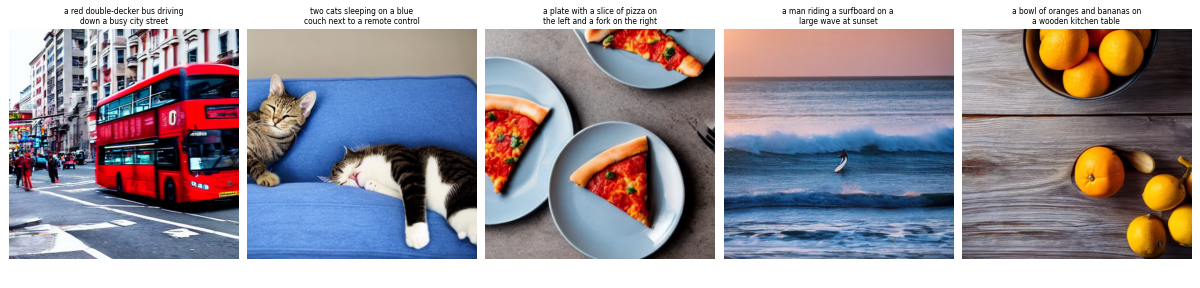

In [36]:
import textwrap
from IPython.display import Image as IPImage

fig, ax = plt.subplots(1, len(images), figsize=(4 * len(images), 4.8))
for a, img, p in zip(ax, images, prompts):
    a.imshow(img); a.axis("off"); a.set_title(textwrap.fill(p, 32), fontsize=9)
plt.tight_layout()
grid_path = OUT_DIR / "grid.png"
plt.savefig(grid_path, dpi=60); plt.close()
display(IPImage(filename=str(grid_path), width=1100))

## 15. Download results
The Colab copy of the repo is deleted when the session ends. Download the zip and copy `results/` (and `docs/dataset_card.md`) into the local repo.

In [37]:
from google.colab import files
shutil.copy(PROC_DIR / "dataset_summary.png", RESULTS_DIR / "dataset_summary.png")

bundle = Path("/content/m1_results")
if bundle.exists(): shutil.rmtree(bundle)
shutil.copytree(RESULTS_DIR, bundle / "results")
(bundle / "docs").mkdir()
shutil.copy(PROC_DIR / "dataset_card.md", bundle / "docs" / "dataset_card.md")
shutil.make_archive("/content/m1_results", "zip", bundle)
files.download("/content/m1_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>